# 02 — Raw race data EDA

**Goal:** understand the raw race laps well enough to write the spec for the processed layer, with the v1 model in mind: **tyre degradation as regression** (see `docs/DECISIONS.md` D9).

The setup cell loads the data; the questions below are prompts to explore. Add notes or answers anywhere, then we discuss them together.

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from f1_intelligence.config import load_ingestion_config

RAW = load_ingestion_config("../configs/ingestion.yaml").storage.raw_uri


def raw_table(table: str, session: str = "R") -> pd.DataFrame:
    """All ingested sessions of one raw table, as a single DataFrame."""
    return duckdb.sql(f"""
        SELECT *
        FROM read_parquet('{RAW}/{table}/**/*.parquet', hive_partitioning = true, union_by_name = true)
        WHERE Session = '{session}'
    """).df()


meta = duckdb.sql(f"""
    SELECT season AS Season, round AS Round, event_name, location, event_format, session_start_utc
    FROM read_json('{RAW}/metadata/**/*.json', hive_partitioning = false)
    WHERE session = 'R'
""").df()

laps = raw_table("laps").merge(meta, on=["Season", "Round"], how="left")
weather = raw_table("weather")
results = raw_table("results")
track_status = raw_table("track_status")
race_control = raw_table("race_control")

print(f"{meta.shape[0]} races | {len(laps):,} laps | seasons {sorted(meta.Season.unique())}")
{name: df.shape for name, df in dict(laps=laps, weather=weather, results=results,
                                      track_status=track_status, race_control=race_control).items()}

92 races | 101,290 laps | seasons [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


{'laps': (101290, 38),
 'weather': (14896, 11),
 'results': (1838, 25),
 'track_status': (1092, 6),
 'race_control': (8156, 12)}

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

## Q1 — What is one row?
- Which columns exist, and what are their dtypes? Anything surprising about how times are stored?
Time is stored as nanosecond it seems, having it in seconds would be better
- How many laps per race?

- Is `(Season, Round, Driver, LapNumber)` unique? (If not, the processed table needs a different key.)
Season, Round, driver, lapNumber they dont seem to be unique. I mean one season has multiple rounds each round has multiple drivers data and each driver then in turn has data for that particular round. So, currently not sure how to handle it

In [4]:
laps.head()

,Season,Round,Session,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,Sector3Time,Sector1SessionTime,Sector2SessionTime,Sector3SessionTime,SpeedI1,SpeedI2,SpeedFL,SpeedST,IsPersonalBest,Compound,TyreLife,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,event_name,location,event_format,session_start_utc
0,2022,1,R,3855340000000,VER,1,100236000000,1.0,1.0,<NA>,<NA>,<NA>,42325000000,24389000000,<NA>,3831046000000,3855427000000,230.0,254.0,274.0,250.0,False,SOFT,4.0,False,Red Bull Racing,3754872000000,NaT,1,2.0,False,,False,False,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00
1,2022,1,R,3953220000000,VER,1,97880000000,2.0,1.0,<NA>,<NA>,31285000000,42269000000,24326000000,3886662000000,3928931000000,3953257000000,230.0,252.0,276.0,296.0,True,SOFT,5.0,False,Red Bull Racing,3855340000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00
2,2022,1,R,4051577000000,VER,1,98357000000,3.0,1.0,<NA>,<NA>,31499000000,42474000000,24384000000,3984756000000,4027230000000,4051614000000,229.0,254.0,276.0,294.0,False,SOFT,6.0,False,Red Bull Racing,3953220000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00
3,2022,1,R,4150143000000,VER,1,98566000000,4.0,1.0,<NA>,<NA>,31342000000,42674000000,24550000000,4082956000000,4125630000000,4150180000000,231.0,250.0,276.0,297.0,False,SOFT,7.0,False,Red Bull Racing,4051577000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00
4,2022,1,R,4249020000000,VER,1,98877000000,5.0,1.0,<NA>,<NA>,31498000000,42854000000,24525000000,4181678000000,4224532000000,4249057000000,229.0,256.0,276.0,293.0,False,SOFT,8.0,False,Red Bull Racing,4150143000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00


In [5]:
# Laps per race
laps.groupby(["Round",])['LapNumber'].max()

Round
1     57.0
2     56.0
3     58.0
4     63.0
5     57.0
6     78.0
7     66.0
8     78.0
9     71.0
10    70.0
11    71.0
12    53.0
13    72.0
14    70.0
15    72.0
16    53.0
17    59.0
18    62.0
19    71.0
20    71.0
21    71.0
22    58.0
23    57.0
24    58.0
Name: LapNumber, dtype: float64

In [6]:
laps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101290 entries, 0 to 101289
Data columns (total 38 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Season              101290 non-null  int64         
 1   Round               101290 non-null  int64         
 2   Session             101290 non-null  object        
 3   Time                101290 non-null  int64         
 4   Driver              101290 non-null  object        
 5   DriverNumber        101290 non-null  object        
 6   LapTime             99751 non-null   Int64         
 7   LapNumber           101290 non-null  float64       
 8   Stint               100936 non-null  float64       
 9   PitOutTime          3467 non-null    Int64         
 10  PitInTime           3469 non-null    Int64         
 11  Sector1Time         99196 non-null   Int64         
 12  Sector2Time         101121 non-null  Int64         
 13  Sector3Time         101008 no

In [7]:
laps.duplicated(subset=['Season', 'Round','LapNumber', 'Driver']).sum()

np.int64(0)

## Q2 — Missing values
- Which columns have NaN / NaT, and how many?
Cell 6
- More important: **in which kind of laps** are they missing? Look at `LapTime` specifically: lap 1? pit laps? something else?
Look at cell 13 looks like lap 2 has most number of null laps. but that is considering all seasons all rounds all drivers. What do you think how it should be done

In [8]:
laps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101290 entries, 0 to 101289
Data columns (total 38 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Season              101290 non-null  int64         
 1   Round               101290 non-null  int64         
 2   Session             101290 non-null  object        
 3   Time                101290 non-null  int64         
 4   Driver              101290 non-null  object        
 5   DriverNumber        101290 non-null  object        
 6   LapTime             99751 non-null   Int64         
 7   LapNumber           101290 non-null  float64       
 8   Stint               100936 non-null  float64       
 9   PitOutTime          3467 non-null    Int64         
 10  PitInTime           3469 non-null    Int64         
 11  Sector1Time         99196 non-null   Int64         
 12  Sector2Time         101121 non-null  Int64         
 13  Sector3Time         101008 no

In [9]:
laps[laps['LapTime'].isnull()].groupby(['TrackStatus'])['LapNumber'].count().sort_values(ascending=False)

TrackStatus
4        625
41       294
1        211
124       66
12        51
451       46
45        46
14        43
6         35
126       25
125       16
671       14
24        11
67         9
51         9
26         7
514        6
1264       5
1254       4
1267       4
65         3
167        2
16         2
1246       1
164        1
16724      1
64         1
651        1
Name: LapNumber, dtype: int64

## Q3 — Track status
- What values does `TrackStatus` take? (Hint: it is a string, and a lap can contain several statuses. Look at `track_status` for what the digits mean.)
I am think like track is running or stopped, maybe safety car is there, or race abandoned something like that
- How do lap times compare between green-flag laps and the others?
Track status

In [10]:
laps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101290 entries, 0 to 101289
Data columns (total 38 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Season              101290 non-null  int64         
 1   Round               101290 non-null  int64         
 2   Session             101290 non-null  object        
 3   Time                101290 non-null  int64         
 4   Driver              101290 non-null  object        
 5   DriverNumber        101290 non-null  object        
 6   LapTime             99751 non-null   Int64         
 7   LapNumber           101290 non-null  float64       
 8   Stint               100936 non-null  float64       
 9   PitOutTime          3467 non-null    Int64         
 10  PitInTime           3469 non-null    Int64         
 11  Sector1Time         99196 non-null   Int64         
 12  Sector2Time         101121 non-null  Int64         
 13  Sector3Time         101008 no

In [11]:
laps['LapTime_sec'] = laps['LapTime'].transform(lambda x: x/1000000000)
laps.groupby('TrackStatus')['LapTime_sec'].mean().sort_values(ascending=False)

TrackStatus
1254     2490.743000
125       164.341583
65        142.422000
45        141.082964
265       140.103400
14        132.423057
41        127.256288
64        123.580616
412       123.206000
4         122.836654
216       122.094647
164       122.038933
1265      121.367143
67        120.858490
6         119.692591
24        117.867071
267       117.086500
124       115.479178
1264      115.126971
2671      114.852286
264       114.686696
712       111.504857
26        111.172502
1267      110.647280
167       109.219226
671       108.872677
126       108.647209
2167      108.631000
6712      105.801750
16        101.313299
12         95.558773
71         93.448782
21         92.467949
214        91.178000
1          89.716445
2          88.976137
1246             NaN
16724            NaN
451              NaN
51               NaN
514              NaN
651              NaN
Name: LapTime_sec, dtype: float64

## Q4 — Pit laps and lap 1
- How much slower are pit-in laps, pit-out laps, and lap 1 compared to a normal lap of the same driver in the same race?
Yeah so look at cell 11 i filtered row before pit in and after pit out and pit in laptime was more than pit out time is what i observed
- Should these laps ever be used to estimate degradation?
i think yes those laps exactly tell us that there was degradation and hence pit stop needed

In [12]:
laps[(laps['Season'] == 2022) & (laps['Round'] == 1) &  (laps['Session'] == 'R')]['Driver'].value_counts()


Driver
ALO    57
PER    57
STR    57
LEC    57
OCO    57
NOR    57
MAG    57
TSU    57
ALB    57
ZHO    57
HUL    57
RIC    57
SAI    57
LAT    57
HAM    57
MSC    57
RUS    57
BOT    57
VER    54
GAS    45
Name: count, dtype: int64

In [13]:
ver_df = laps[(laps['Season'] == 2022) & (laps['Round'] == 1) & (laps['Driver'] == 'VER') & (laps['Session'] == 'R')]
lec_df = laps[(laps['Season'] == 2022) & (laps['Round'] == 1) & (laps['Driver'] == 'LEC') & (laps['Session'] == 'R')]
ham_df = laps[(laps['Season'] == 2022) & (laps['Round'] == 1) & (laps['Driver'] == 'HAM') & (laps['Session'] == 'R')]
target_mask = ver_df['PitInTime'].notnull() | ver_df['PitOutTime'].notnull()
combined_mask = target_mask | target_mask.shift(-1, fill_value=False) | target_mask.shift(1, fill_value=False)
ver_df[combined_mask].head(100)

,Season,Round,Session,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,Sector3Time,Sector1SessionTime,Sector2SessionTime,Sector3SessionTime,SpeedI1,SpeedI2,SpeedFL,SpeedST,IsPersonalBest,Compound,TyreLife,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate,event_name,location,event_format,session_start_utc,LapTime_sec
12,2022,1,R,5043180000000,VER,1,99534000000,13.0,1.0,<NA>,<NA>,31809000000,43082000000,24643000000,4975492000000,5018574000000,5043217000000,228.0,251.0,275.0,290.0,False,SOFT,16.0,False,Red Bull Racing,4943646000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,99.534
13,2022,1,R,5145230000000,VER,1,102050000000,14.0,1.0,<NA>,5143479000000,31831000000,43137000000,27082000000,5075048000000,5118185000000,5145267000000,229.0,253.0,NaN,292.0,False,SOFT,17.0,False,Red Bull Racing,5043180000000,NaT,1,2.0,False,,False,False,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,102.050
14,2022,1,R,5262639000000,VER,1,117409000000,15.0,2.0,5168393000000,<NA>,52162000000,41525000000,23722000000,5197429000000,5238954000000,5262676000000,227.0,257.0,276.0,208.0,False,SOFT,1.0,True,Red Bull Racing,5145230000000,NaT,12,4.0,False,,False,False,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,117.409
15,2022,1,R,5359544000000,VER,1,96905000000,16.0,2.0,<NA>,<NA>,30944000000,41970000000,23991000000,5293620000000,5335590000000,5359581000000,231.0,260.0,286.0,300.0,True,SOFT,2.0,True,Red Bull Racing,5262639000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,96.905
28,2022,1,R,6637485000000,VER,1,99384000000,29.0,2.0,<NA>,<NA>,31569000000,43286000000,24529000000,6569707000000,6612993000000,6637522000000,232.0,258.0,279.0,298.0,False,SOFT,15.0,True,Red Bull Racing,6538101000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,99.384
29,2022,1,R,6739022000000,VER,1,101537000000,30.0,2.0,<NA>,6737298000000,31548000000,43074000000,26915000000,6669070000000,6712144000000,6739059000000,233.0,258.0,NaN,300.0,False,SOFT,16.0,True,Red Bull Racing,6637485000000,NaT,1,2.0,False,,False,False,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,101.537
30,2022,1,R,6856261000000,VER,1,117239000000,31.0,3.0,6762243000000,<NA>,52026000000,41486000000,23727000000,6791085000000,6832571000000,6856298000000,232.0,256.0,279.0,218.0,False,MEDIUM,1.0,True,Red Bull Racing,6739022000000,NaT,1,4.0,False,,False,False,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,117.239
31,2022,1,R,6952788000000,VER,1,96527000000,32.0,3.0,<NA>,<NA>,30783000000,41843000000,23901000000,6887081000000,6928924000000,6952825000000,234.0,251.0,281.0,294.0,True,MEDIUM,2.0,True,Red Bull Racing,6856261000000,NaT,1,4.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,96.527
41,2022,1,R,7922732000000,VER,1,97855000000,42.0,3.0,<NA>,<NA>,31209000000,42500000000,24146000000,7856123000000,7898623000000,7922769000000,233.0,261.0,280.0,304.0,False,MEDIUM,12.0,True,Red Bull Racing,7824877000000,NaT,1,2.0,False,,False,True,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,97.855
42,2022,1,R,8022519000000,VER,1,99787000000,43.0,3.0,<NA>,8020852000000,31188000000,42249000000,26350000000,7953957000000,7996206000000,8022556000000,234.0,260.0,NaN,305.0,False,MEDIUM,13.0,True,Red Bull Racing,7922732000000,NaT,1,2.0,False,,False,False,Bahrain Grand Prix,Sakhir,conventional,2022-03-20 15:00:00,99.787


In [14]:
laps.groupby(["Season", "Round", "Driver"])['LapTime_sec'].shift(1)

0              NaN
1          100.236
2           97.880
3           98.357
4           98.566
5           98.877
6           98.940
7           99.062
8           99.092
9           99.251
10          99.392
11          99.479
12          99.410
13          99.534
14         102.050
15         117.409
16          96.905
17          97.587
18          97.717
19          97.728
20          98.257
21          98.294
22          98.243
23          98.091
24          98.187
25          98.372
26          98.476
27          98.823
28          98.782
29          99.384
30         101.537
31         117.239
32          96.527
33          96.347
34          96.384
35          96.731
36          96.920
37          96.962
38          96.898
39          97.255
40          97.308
41          97.284
42          97.855
43          99.787
44         117.242
45          95.747
46         129.941
47         134.782
48             NaN
49         145.374
50         144.508
51          95.440
52          

## Q5 — Outliers and what is "normal"
- Plot the lap-time distribution for a few races. What does a normal lap look like at each track?
i actually disnt understand what you meant here but i have plotted for like three drivers from a particular season and round how their laptime progression looks like throughout the race
- After removing the laps from Q2–Q4, are there still outliers? What are they? (Look at `Deleted`, `IsAccurate`.)
- Lap times differ by track. Does that matter for one model across all races?
i think yes differing lap times matter. but thats could be because the track length is too long, so i think we would need to normalize it somehow, i mean higher track length giving higher track time shouldnt cause problem that would fiddle with the siisue of higher tyre degradation higher lap time

In [15]:
laps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101290 entries, 0 to 101289
Data columns (total 39 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Season              101290 non-null  int64         
 1   Round               101290 non-null  int64         
 2   Session             101290 non-null  object        
 3   Time                101290 non-null  int64         
 4   Driver              101290 non-null  object        
 5   DriverNumber        101290 non-null  object        
 6   LapTime             99751 non-null   Int64         
 7   LapNumber           101290 non-null  float64       
 8   Stint               100936 non-null  float64       
 9   PitOutTime          3467 non-null    Int64         
 10  PitInTime           3469 non-null    Int64         
 11  Sector1Time         99196 non-null   Int64         
 12  Sector2Time         101121 non-null  Int64         
 13  Sector3Time         101008 no

In [16]:
print(laps['IsAccurate'].value_counts())
print(laps['Deleted'].value_counts())
print(laps['DeletedReason'].value_counts())

IsAccurate
True     87522
False    13768
Name: count, dtype: int64
Deleted
False    100017
True       1273
Name: count, dtype: int64
DeletedReason
                                             99919
TRACK LIMITS AT TURN 10 (NEXT LAP)              43
TRACK LIMITS AT TURN 2                          11
TRACK LIMITS AT TURN 1 LAP 5                     9
TRACK LIMITS AT TURN 9 LAP 14                    8
TRACK LIMITS AT TURN 10 LAP 13                   7
TRACK LIMITS AT TURN 1 LAP 10                    6
TRACK LIMITS AT TURN 20 (NEXT LAP)               6
TRACK LIMITS AT TURN 1 LAP 9                     6
TRACK LIMITS AT TURN 16 (NEXT LAP)               6
TRACK LIMITS AT TURN 10 LAP 8                    6
TRACK LIMITS AT TURN 4 LAP 7                     6
TRACK LIMITS AT TURN 1 LAP 14                    6
TRACK LIMITS AT TURN 1 LAP 29                    6
TRACK LIMITS AT TURN 1 LAP 4                     5
TRACK LIMITS AT TURN 2 LAP 19                    5
TRACK LIMITS AT TURN 9 LAP 5         

In [17]:
import matplotlib.pyplot as plt

ver_df['LapTime_sec'] = ver_df['LapTime'].transform(lambda x: x / 1000000000)
lec_df['LapTime_sec'] = lec_df['LapTime'].transform(lambda x: x / 1000000000)
ham_df['LapTime_sec'] = ham_df['LapTime'].transform(lambda x: x / 1000000000)

/tmp/ipykernel_951515/1230361228.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ver_df['LapTime_sec'] = ver_df['LapTime'].transform(lambda x: x / 1000000000)
/tmp/ipykernel_951515/1230361228.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lec_df['LapTime_sec'] = lec_df['LapTime'].transform(lambda x: x / 1000000000)
/tmp/ipykernel_951515/1230361228.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

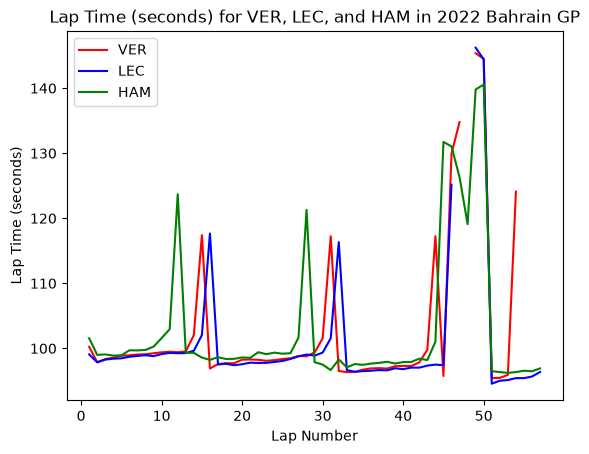

In [18]:
plt.plot(ver_df['LapNumber'], ver_df['LapTime_sec'], label='VER', color='red')
plt.plot(lec_df['LapNumber'], lec_df['LapTime_sec'], label='LEC', color='blue')
plt.plot(ham_df['LapNumber'], ham_df['LapTime_sec'], label='HAM', color='green')
plt.title("Lap Time (seconds) for VER, LEC, and HAM in 2022 Bahrain GP")
plt.xlabel("Lap Number")
plt.ylabel("Lap Time (seconds)")
plt.legend()

(array([ 4.,  8.,  8.,  9., 12.,  2.,  0.,  2.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         3.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,
         0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.]),
 array([ 95.44      ,  96.27223333,  97.10446667,  97.9367    ,
         98.76893333,  99.60116667, 100.4334    , 101.26563333,
        102.09786667, 102.9301    , 103.76233333, 104.59456667,
        105.4268    , 106.25903333, 107.09126667, 107.9235    ,
        108.75573333, 109.58796667, 110.4202    , 111.25243333,
        112.08466667, 112.9169    , 113.74913333, 114.58136667,
        115.4136    , 116.24583333, 117.07806667, 117.9103    ,
        118.74253333, 119.57476667, 120.407     , 121.23923333,
        122.07146667, 122.9037    , 123.73593333, 124.56816667,
        125.4004    , 126.23263333, 127.06486667, 127.8971    ,
        128.729333

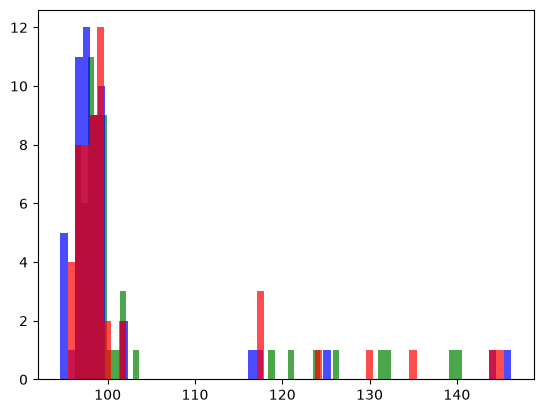

In [19]:
plt.hist(ham_df['LapTime_sec'], bins=60, color='green', alpha=0.7)
plt.hist(lec_df['LapTime_sec'], bins=60, color='blue', alpha=0.7)
plt.hist(ver_df['LapTime_sec'], bins=60, color='red', alpha=0.7)

## Q6 — Tyres and stints
- Which compounds appear, including wet ones? How many laps on each?
cell 23
- Does `TyreLife` start at 1 for every stint, or higher for used sets? (Check `FreshTyre`.)
TyreLife is growing with lap number usually, but some starting laps have higher tyre life not sure why. yeah and fresh tyre later in the race goes down. 
- How many stints per driver per race? Any stints too short to say anything about degradation?
stint grows with lap number. so i am guessing it is also a measure of degradation. but since we change tyres it doesnt reset but grows after tyre change. it is my guess

In [20]:
laps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101290 entries, 0 to 101289
Data columns (total 39 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Season              101290 non-null  int64         
 1   Round               101290 non-null  int64         
 2   Session             101290 non-null  object        
 3   Time                101290 non-null  int64         
 4   Driver              101290 non-null  object        
 5   DriverNumber        101290 non-null  object        
 6   LapTime             99751 non-null   Int64         
 7   LapNumber           101290 non-null  float64       
 8   Stint               100936 non-null  float64       
 9   PitOutTime          3467 non-null    Int64         
 10  PitInTime           3469 non-null    Int64         
 11  Sector1Time         99196 non-null   Int64         
 12  Sector2Time         101121 non-null  Int64         
 13  Sector3Time         101008 no

In [21]:
laps['Compound'].value_counts()

Compound
HARD            44364
MEDIUM          36980
SOFT            12760
INTERMEDIATE     5945
WET               461
None              426
nan               354
Name: count, dtype: int64

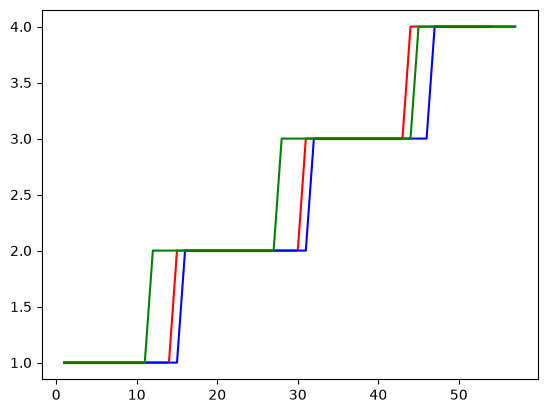

In [22]:
plt.plot(ver_df['LapNumber'], ver_df['Stint'], label='VER', color='red')
plt.plot(lec_df['LapNumber'], lec_df['Stint'], label='LEC', color='blue')
plt.plot(ham_df['LapNumber'], ham_df['Stint'], label='HAM', color='green')


In [23]:
laps.groupby('LapNumber')['FreshTyre'].value_counts()

LapNumber  FreshTyre
1.0        True         1511
           False         315
2.0        True         1449
           False         335
3.0        True         1416
           False         363
4.0        True         1415
           False         363
5.0        True         1413
           False         362
6.0        True         1412
           False         361
7.0        True         1407
           False         360
8.0        True         1401
           False         359
9.0        True         1394
           False         363
10.0       True         1385
           False         370
11.0       True         1387
           False         366
12.0       True         1391
           False         361
13.0       True         1399
           False         352
14.0       True         1400
           False         349
15.0       True         1421
           False         327
16.0       True         1423
           False         318
17.0       True         1427
           False      

## Q7 — Weather
- How often is weather sampled? (Look at `Time` differences in `weather` for one race.)
- How much does track temperature change within a race? Across races?
- Any rain (`Rainfall`)? Which races?

In [24]:
season_22_df = weather[(weather['Season'] == 2022) & (weather['Round'] == 1) & (weather['Session'] == 'R')]
season_22_df.head(10)
season_22_df['Time_sec'] = season_22_df['Time'].transform(lambda x: x / 1000000000)
season_22_df.shape

/tmp/ipykernel_951515/1283318333.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  season_22_df['Time_sec'] = season_22_df['Time'].transform(lambda x: x / 1000000000)


(163, 12)

<Axes: >

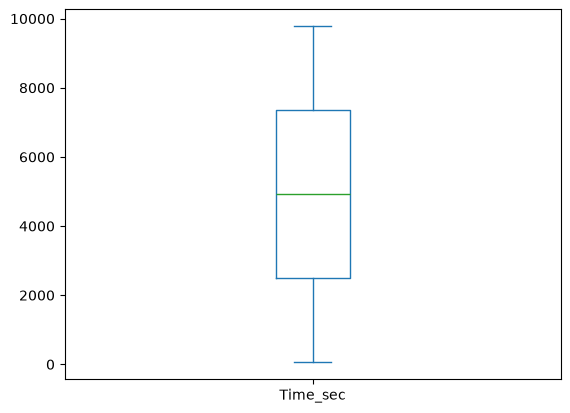

In [25]:
season_22_df['Time_sec'].plot.box()

In [26]:
season_22_df['Time_sec'].diff().mean()

np.float64(60.00322222222223)

In [54]:
season_22_df['Time_sec'].describe()

count     163.000000
mean     4923.501202
std      2832.085637
min        63.204000
25%      2493.328500
50%      4923.519000
75%      7353.722000
max      9783.726000
Name: Time_sec, dtype: float64

In [27]:
season_22_df['TrackTemp'].describe()

count    163.000000
mean      28.610429
std        1.853845
min       26.300000
25%       27.000000
50%       27.900000
75%       30.350000
max       32.300000
Name: TrackTemp, dtype: float64

<Axes: >

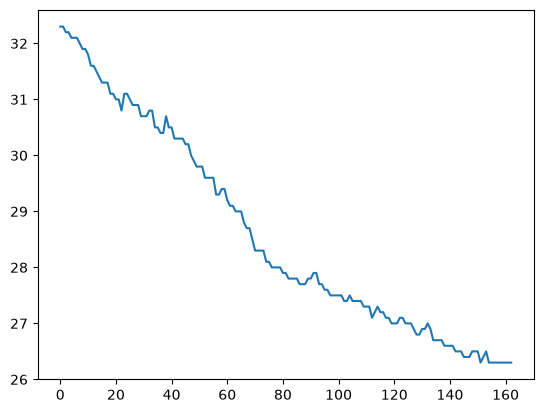

In [28]:
season_22_df['TrackTemp'].plot()

<Axes: >

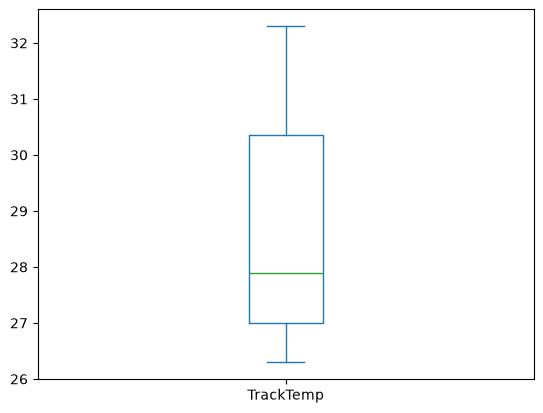

In [29]:
season_22_df['TrackTemp'].plot.box()

In [30]:
weather.groupby(['Season', 'Round', 'Session'])['TrackTemp'].mean().describe()

count    92.000000
mean     35.452995
std       8.937975
min      17.418987
25%      29.587879
50%      35.563023
75%      42.846866
max      54.461719
Name: TrackTemp, dtype: float64

In [31]:
weather.groupby(['Season','Round','Rainfall'])[['TrackTemp']].agg({'TrackTemp': ['mean', 'std']})

TrackTemp          
                            mean       std
Season Round Rainfall                     
2022   1     False     28.610429  1.853845
       2     False     28.409211  0.773001
       3     False     37.408333  2.308999
       4     False     17.418987  0.992144
       5     False     42.996078  2.668798
             True      39.822222  2.926934
       6     False     48.957317  0.491531
       7     False     32.466667  5.094542
             True      29.196262  2.164200
       8     False     47.149689  1.833444
       9     False     41.261111  0.932455
       10    False     30.115464  1.754865
             True      28.100000  0.287228
       11    False     30.746711  1.534889
       12    False     54.461719  3.707157
       13    False     27.225620  0.980096
             True      25.393478  1.191899
       14    False     36.083974  0.697784
       15    False     33.446012  0.630818
       16    False     43.138776  0.590617
       17    False     29.357416  1.034898
             True      27.228261  1.281087
       18    False     18.280000  0.044721
             True      19.963600  1.481884
       19    False     35.523529  1.262256
       20    False     41.689091  3.872338
       21    False     46.049102  5.137142
       22    False     34.310323  1.934820
2023   1     False     31.011801  1.772441
       2     False     31.792568  1.225638
       3     False     30.139640  3.977363
       4     False     41.210000  2.419631
       5     False     36.689032  4.387890
       6     False     40.835333  5.847722
             True      30.142308  2.836501
       7     False     33.838961  5.010842
       8     False     30.593210  1.875773
       9     False     32.068667  0.989755
             True      31.333333  0.850490
       10    False     30.941060  2.619549
       11    False     48.579268  1.460081
       12    False     28.403597  1.380055
             True      26.181818  1.033265
       13    False     25.738509  3.109563
             True      22.266667  3.177269
       14    False     42.928205  0.705078
       15    False     36.422159  1.095820
       16    False     42.070253  3.430057
       17    False     36.932075  0.790315
       18    False     40.628571  0.776846
       19    False     45.639474  2.985072
       20    False     46.765934  4.047009
             True      48.600000       NaN
       21    False     17.994444  0.442346
       22    False     33.460897  2.205552
2024   1     False     23.652866  1.323678
       2     False     31.593151  1.058213
       3     False     38.402083  0.689428
       4     False     37.501105  2.799464
       5     False     29.792727  1.458180
       6     False     44.664000  2.525156
       7     False     42.023776  1.763358
       8     False     46.318000  2.698516
       9     False     25.806098  1.838702
             True      21.300000  1.119226
       10    False     41.111765  1.044657
             True      38.700000       NaN
       11    False     46.422535  1.375799
             True      46.200000       NaN
       12    False     29.601042  5.038849
             True      24.035294  4.016009
       13    False     44.916129  2.242027
       14    False     42.267153  1.342140
       15    False     30.805882  1.395257
       16    False     49.311278  3.775532
       17    False     44.349342  2.039121
       18    False     36.445625  1.070699
       19    False     46.601935  0.922410
       20    False     35.602516  2.916452
       21    False     26.608333  2.000434
             True      25.167521  0.967741
       22    False     17.723776  0.731481
       23    False     22.773510  0.616950
       24    False     31.805405  1.984456
2025   1     False     18.936667  0.231884
             True      18.953448  0.353040
       2     False     35.816883  3.539687
       3     False     20.514286  1.096992
       4     False     31.870253  1.295682
       5     False     37.819718  0.910010
       6     False     3

## Q8 — Fuel effect
- Using only "clean" laps (your answers to Q2–Q5), plot lap time vs `LapNumber` for one race.
- Does the car get faster as fuel burns, even while tyres age? Roughly how much per lap?
in lap time vs lap number the car actually gets slower gradually with increasing lao number and i think its the pit stop that makes it faster again. do they actually refuel at every pit stop? i dont know but currently in the data there is no evidence to show that the car is wlower because of low feul, and if it it it should actually just be correlated to lap number
- Why does this matter for estimating degradation? (Recall the −0.04 correlation of `TyreLife` with lap time in your first notebook.)
i dont remember this


In [36]:
laps.columns

Index(['Season', 'Round', 'Session', 'Time', 'Driver', 'DriverNumber',
       'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime',
       'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime',
       'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2',
       'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife',
       'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus',
       'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate',
       'event_name', 'location', 'event_format', 'session_start_utc',
       'LapTime_sec'],
      dtype='object')

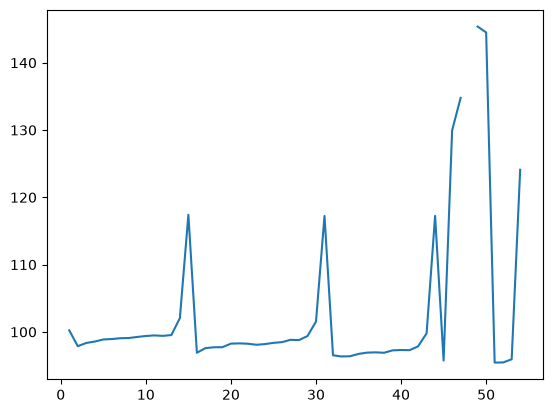

In [38]:
s22_r1_df = laps[(laps['Season'] == 2022) & (laps['Round'] == 1) & (laps['Session'] == 'R') & (laps['Driver'] == 'VER')]
plt.plot( s22_r1_df['LapNumber'],s22_r1_df['LapTime_sec'], label='Lap Time')

## Q9 — Traffic
- For one race, compute each driver's gap to the car ahead on every lap. (Hint: `Time` is when the driver crossed the line; `Position` tells you who is ahead.)
- Plot gap vs lap time. Is there a gap below which drivers are visibly slower?

In [41]:
s22_r1_df = laps[(laps['Season'] == 2022) & (laps['Round'] == 1) & (laps['Session'] == 'R')]

s22_r1_df['Time_sec'] = s22_r1_df['Time'].transform(lambda x: x / 1000000000)


/tmp/ipykernel_951515/794928400.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  s22_r1_df['Time_sec'] = s22_r1_df['Time'].transform(lambda x: x / 1000000000)


In [60]:
s22_r1_df[['Driver','LapNumber', 'Time_sec', 'Position']].groupby(['Driver','LapNumber','Time_sec'])['Position'].mean()


Driver  LapNumber  Time_sec
ALB     1.0        3862.740    11.0
        2.0        3963.288    11.0
        3.0        4063.952    11.0
        4.0        4165.078    11.0
        5.0        4267.381    12.0
        6.0        4369.089    12.0
        7.0        4470.650    12.0
        8.0        4573.747    13.0
        9.0        4675.896    13.0
        10.0       4779.396    14.0
        11.0       4881.984    14.0
        12.0       4984.489    13.0
        13.0       5089.241    14.0
        14.0       5210.316    20.0
        15.0       5309.833    19.0
        16.0       5409.997    19.0
        17.0       5510.262    19.0
        18.0       5610.487    18.0
        19.0       5711.287    16.0
        20.0       5811.526    16.0
        21.0       5912.707    16.0
        22.0       6013.523    15.0
        23.0       6114.259    15.0
        24.0       6214.928    15.0
        25.0       6315.960    15.0
        26.0       6417.588    15.0
        27.0       6519.641    16.0


In [44]:
s22_r1_df['LapTime_sec'].describe()

count    1118.000000
mean      102.904558
std         9.417679
min        94.570000
25%        98.491750
50%        99.826000
75%       101.871750
max       149.264000
Name: LapTime_sec, dtype: float64

In [52]:
s22_r1_df.groupby(['Driver','LapNumber','Time_sec'])['Position'].mean()

Driver  LapNumber  Time_sec
ALB     1.0        3862.740    11.0
        2.0        3963.288    11.0
        3.0        4063.952    11.0
        4.0        4165.078    11.0
        5.0        4267.381    12.0
        6.0        4369.089    12.0
        7.0        4470.650    12.0
        8.0        4573.747    13.0
        9.0        4675.896    13.0
        10.0       4779.396    14.0
        11.0       4881.984    14.0
        12.0       4984.489    13.0
        13.0       5089.241    14.0
        14.0       5210.316    20.0
        15.0       5309.833    19.0
        16.0       5409.997    19.0
        17.0       5510.262    19.0
        18.0       5610.487    18.0
        19.0       5711.287    16.0
        20.0       5811.526    16.0
        21.0       5912.707    16.0
        22.0       6013.523    15.0
        23.0       6114.259    15.0
        24.0       6214.928    15.0
        25.0       6315.960    15.0
        26.0       6417.588    15.0
        27.0       6519.641    16.0


## Q10 — The target: lap time vs tyre age
- For clean laps, plot lap time vs `TyreLife` per compound, for a few races.
- Fit a simple slope per stint (like your first notebook). How do slopes differ by compound and track?
- What would you need to correct for (Q8, Q9, track) before a slope means "degradation"?

## Notes / open questions
